# Zhou et al. (2021): multi-task V-Net for ABUS tumor segmentation and classification

**Paper.** Y. Zhou, H. Chen, Y. Li, Q. Liu, X. Xu, S. Wang, D. Shen, P.-T. Yap. *Multi-task learning for segmentation
and classification of tumors in 3D automated breast ultrasound images.* Medical Image Analysis 70:101918, 2021.
[doi:10.1016/j.media.2020.101918](https://doi.org/10.1016/j.media.2020.101918)

**Method.** One 3D V-Net does two jobs at once. The encoder-decoder segments the tumor. A light classification
branch taps three scales of the same network (Stage 4: deepest encoder, Stage 5: bottleneck, Stage 6: first
decoder stage), pools each, L2-normalises it and concatenates them for a benign/malignant decision. The network is run
**iteratively** (N = 2): the tumor probability map of the first pass is added to the input of the second pass, so the
second pass sees where the first one thought the tumor was. The loss is a weighted sum of a class-weighted focal loss
(classification) and a Dice loss (segmentation).

**What we implement:** Sec. 3.1 (V-Net backbone), 3.2 and Fig. 2b (multi-scale classification branch, Eq. 1),
3.3 and Alg. 1 (iterative feature refining, N = 2), Eq. 2-3 (class-weighted focal loss), Eq. 4 (Dice loss) and Eq. 5
(combined loss, lambda = 0.3). Code: `abus_classification/papers/zhou2021/` (`model.py`, `losses.py`, `train.py`).

**How this notebook runs.** Nothing here trains or tests the network. The training and the test predictions come
from the Kaggle kernel `simayousef/zhou2021-multitask` and are stored in `../results/zhou2021/`. The cells below only
load those files, draw the architecture, show example lesions from the TDSC-ABUS data (through
`tdsc_abus2023_pytorch`) and run cheap checks of the code (shapes, parameter count, hand-computed losses). Every cell
can be re-run in a few seconds.

1. [Setup](#1-setup)
2. [Implementation details: paper vs ours](#2-implementation-details-paper-vs-ours)
3. [Network architecture](#3-network-architecture)
4. [Verification of the implementation](#4-verification-of-the-implementation)
5. [Data: example lesions and what the network sees](#5-data-example-lesions-and-what-the-network-sees)
6. [Results (Kaggle)](#6-results-kaggle)
7. [Protocol and how to re-run](#7-protocol-and-how-to-re-run)
8. [Open issues](#8-open-issues)

## 1. Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.metrics import roc_auc_score, roc_curve
from tdsc_abus2023_pytorch import TDSC, DataSplits

from abus_classification.data.lesion_cache import ISO, PATCH, patch
from abus_classification.papers.zhou2021.losses import dice_loss, focal_loss
from abus_classification.papers.zhou2021.model import MultiTaskVNet
from abus_classification.papers.zhou2021.train import augment
from abus_classification.protocol import auc_ci, metrics
from abus_classification.utils.spacing import TDSC_SPACING

RESULTS = Path("../results/zhou2021")
DATA_ROOT = Path("../data/tdsc")
SEEDS = (0, 1, 2)

In [2]:
# palette shared with notebooks/1-tao2013.ipynb
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MALIGNANT, BENIGN = "#eb6834", "#2a78d6"
ACCENT, REFERENCE = "#4a3aa7", "#a8a69f"
SEED_COLORS = ["#4a3aa7", "#008300", "#e87ba4"]

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.labelsize": 9.5, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})


def fig_title(fig, title, subtitle=None, x=0.008):
    """Figure title + subtitle spaced in inches; returns the tight_layout rect top."""
    h = fig.get_figheight()
    fig.suptitle(title, x=x, y=1 - 0.26 / h, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    if subtitle:
        fig.text(x, 1 - 0.58 / h, subtitle, ha="left", va="top", fontsize=9.5, color=INK_2)
    return 1 - (0.92 if subtitle else 0.62) / h


def value_grid(ax, axis="y"):
    ax.grid(True, axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

## 2. Implementation details: paper vs ours

| | Paper (Zhou et al. 2021) | Ours |
|---|---|---|
| **Data** | Private: 170 ABUS volumes from 107 patients, about 2 malignant per benign (Sec. 3.4, 4.1) | TDSC-ABUS 2023: 200 volumes, one lesion each |
| **Split** | Four-fold cross-validation, split by patient (Sec. 4.1) | Train+Validation (130) for training, official Test (70) for reporting |
| **Input** | 64 x 32 x 64 mm around the tumor center at 0.5 mm: 128 x 64 x 128 voxels (Sec. 4.1) | 61 x 30 x 38 mm at 0.476 mm: 128 x 64 x 80 voxels (shared lesion cache), so 40% less field of view on one axis |
| **Backbone** | V-Net, 2x2x2 strided convs for down-sampling, BN + ReLU (Sec. 3.1) | Same; 4 encoder stages (16-32-64-128 channels), bottleneck 256, 3 convs in the bottleneck |
| **Classification branch** | Stage 4, 5, 6 -> GAP -> L2 norm (Eq. 1) -> concat -> 2 FC -> softmax (Fig. 2b) | Same, with a 512 -> 256 -> 1 head and a sigmoid (equivalent to a 2-way softmax) |
| **FC width, dropout** | Not given | 256, dropout 0.5 |
| **Iterative refining** | N = 2, previous probability map added to the input (Alg. 1) | N = 2, input + probability map, one Adam step per pass |
| **Loss** | lambda L_focal + (1 - lambda) L_Dice, lambda = 0.3 (Eq. 2-5, Table 5) | Same |
| **Focal loss** | gamma = 2, class weights w_m = N_n / (N_m + N_n) (Eq. 3) | Same, weights from the 130 training labels |
| **Optimiser** | Adam, lr 1e-4 with decay, batch size 2 | Adam 1e-4, cosine decay, batch size 2 |
| **Epochs** | Not given | 100 |
| **Augmentation** | Rotation 0-360 degrees, flips, elastic, scaling (Sec. 4.2) | Random flips on all axes + isotropic scaling 0.8-1.2 (no rotation, no elastic) |
| **Segmentation output** | argmax (Alg. 1) | threshold 0.5 on one sigmoid output, equivalent |
| **Seeds** | Not stated; metrics over the four folds | 3 seeds (0, 1, 2), reported per seed and as the mean of the three probabilities |

## 3. Network architecture

The V-Net is drawn below with the shapes it actually has for one of our 128 x 64 x 80 patches. The three tapped
stages for the classification branch are highlighted. The second pass (dashed loop) adds the first pass's tumor
probability map to the input volume.

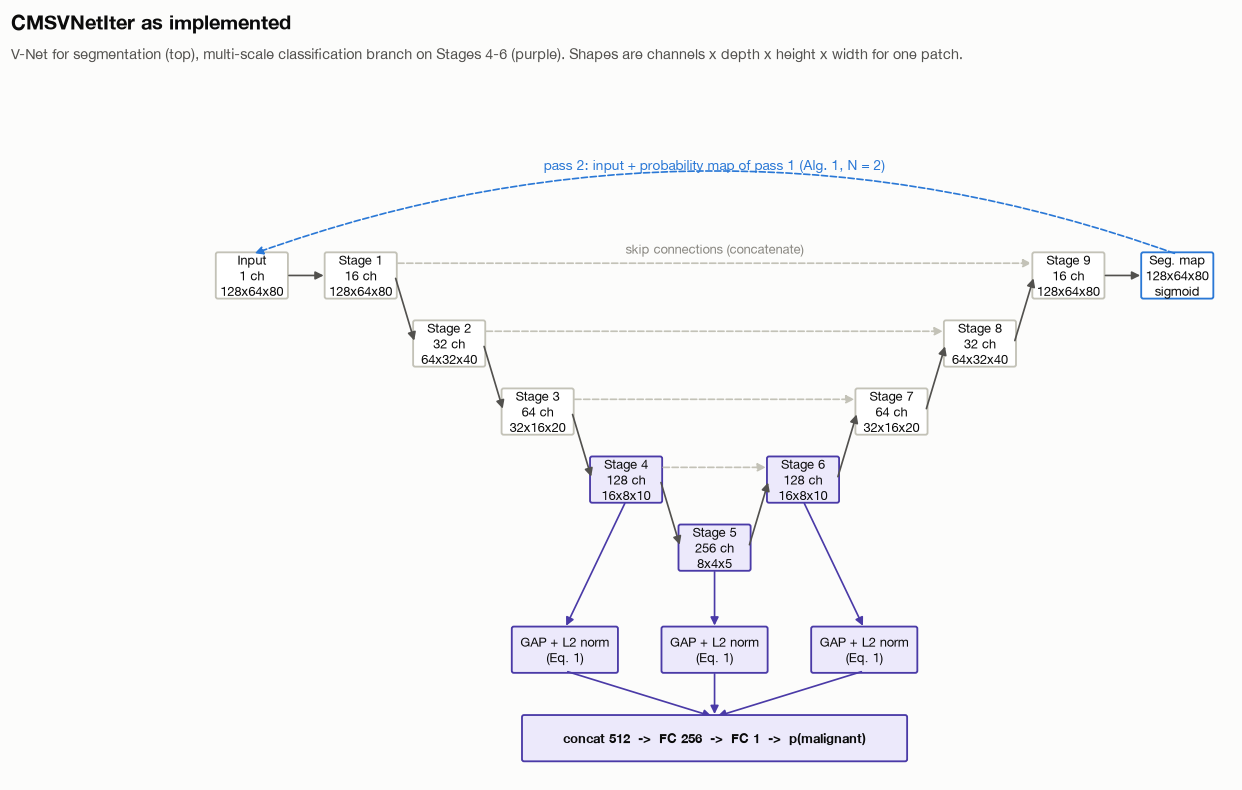

In [3]:
net = MultiTaskVNet().eval()
x = torch.zeros(1, 1, *PATCH)
shapes = {}
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.__setitem__(n, tuple(o.shape[1:])))
         for n, m in [*[(f"enc{k}", e) for k, e in enumerate(net.enc)], ("mid", net.mid),
                      *[(f"dec{k}", d) for k, d in enumerate(net.dec)], ("seg", net.seg)]]
with torch.no_grad():
    seg, logit = net(x)
for h in hooks:
    h.remove()

fmt = lambda s: f"{s[0]} ch\n{s[1]}x{s[2]}x{s[3]}"
stages = [("Stage 1", shapes["enc0"]), ("Stage 2", shapes["enc1"]), ("Stage 3", shapes["enc2"]),
          ("Stage 4", shapes["enc3"]), ("Stage 5", shapes["mid"]), ("Stage 6", shapes["dec0"]),
          ("Stage 7", shapes["dec1"]), ("Stage 8", shapes["dec2"]), ("Stage 9", shapes["dec3"])]
pos = [(0, 4), (1.3, 3), (2.6, 2), (3.9, 1), (5.2, 0), (6.5, 1), (7.8, 2), (9.1, 3), (10.4, 4)]
tapped = {"Stage 4", "Stage 5", "Stage 6"}

fig, ax = plt.subplots(figsize=(13, 7.4))
W, H = 1.0, 0.62


def box(xy, text, face, edge, w=W, h=H, color=INK, weight="normal"):
    ax.add_patch(FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h, boxstyle="round,pad=0.03",
                                fc=face, ec=edge, lw=1.2))
    ax.text(*xy, text, ha="center", va="center", fontsize=8.5, color=color, weight=weight)


def arrow(a, b, color=INK_2, style="-|>", ls="-", rad=0.0):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=style, mutation_scale=11, color=color, lw=1.1,
                                 linestyle=ls, connectionstyle=f"arc3,rad={rad}"))


for (name, s), p in zip(stages, pos):
    on = name in tapped
    box(p, f"{name}\n{fmt(s)}", "#ece9fb" if on else "white", ACCENT if on else AXIS)
for a, b in zip(pos, pos[1:]):
    arrow((a[0] + W / 2, a[1]), (b[0] - W / 2, b[1]))
for k in range(4):                                   # skip connections
    arrow((pos[k][0] + W / 2, pos[k][1] + 0.18), (pos[8 - k][0] - W / 2, pos[8 - k][1] + 0.18),
          color=AXIS, ls="--")
ax.text(5.2, 4.32, "skip connections (concatenate)", ha="center", fontsize=8.5, color=MUTED)

inp = (-1.6, 4)
box(inp, "Input\n1 ch\n128x64x80", "white", AXIS)
arrow((inp[0] + W / 2, 4), (pos[0][0] - W / 2, 4))
out = (12.0, 4)
box(out, "Seg. map\n" + fmt(shapes["seg"]).split("\n")[1] + "\nsigmoid", "white", BENIGN)
arrow((pos[8][0] + W / 2, 4), (out[0] - W / 2, 4))
arrow((out[0], 4 + H / 2), (inp[0], 4 + H / 2), color=BENIGN, ls="--", rad=0.18)
ax.text(5.2, 5.55, "pass 2: input + probability map of pass 1 (Alg. 1, N = 2)", ha="center", fontsize=9,
        color=BENIGN)

gap = [(3.0, -1.5), (5.2, -1.5), (7.4, -1.5)]
for g, src in zip(gap, (pos[3], pos[4], pos[5])):
    arrow((src[0], src[1] - H / 2), (g[0], g[1] + H / 2), color=ACCENT)
    box(g, "GAP + L2 norm\n(Eq. 1)", "#ece9fb", ACCENT, w=1.5)
cat = (5.2, -2.8)
for g in gap:
    arrow((g[0], g[1] - H / 2), (cat[0], cat[1] + H / 2), color=ACCENT)
box(cat, f"concat {net.cls[0].in_features}  ->  FC {net.cls[0].out_features}  ->  FC 1  ->  p(malignant)",
    "#ece9fb", ACCENT, w=5.6, weight="bold")

ax.set_xlim(-2.4, 12.8); ax.set_ylim(-3.4, 6.0)
ax.set_aspect("equal"); bare(ax)
top = fig_title(fig, "CMSVNetIter as implemented",
                "V-Net for segmentation (top), multi-scale classification branch on Stages 4-6 (purple). "
                "Shapes are channels x depth x height x width for one patch.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

In [4]:
n_params = sum(p.numel() for p in net.parameters())
n_cls = sum(p.numel() for p in net.cls.parameters())
print(f"parameters: {n_params:,} in total, {n_cls:,} in the classification head ({100 * n_cls / n_params:.1f}%)")
pd.DataFrame({"output shape (C, D, H, W)": shapes}).rename_axis("block")

parameters: 7,724,002 in total, 131,585 in the classification head (1.7%)


,"output shape (C, D, H, W)"
block,
enc0,"(16, 128, 64, 80)"
enc1,"(32, 64, 32, 40)"
enc2,"(64, 32, 16, 20)"
enc3,"(128, 16, 8, 10)"
mid,"(256, 8, 4, 5)"
dec0,"(128, 16, 8, 10)"
dec1,"(64, 32, 16, 20)"
dec2,"(32, 64, 32, 40)"
dec3,"(16, 128, 64, 80)"


## 4. Verification of the implementation

Cheap checks that the code does what the paper says. They do not train anything.

**4.1 Shapes.** Segmentation output has the input's spatial size, the classifier gives one logit per volume, and the
classification branch concatenates Stage 4 (128) + Stage 5 (256) + Stage 6 (128) = 512 features (Fig. 2b).

In [5]:
assert seg.shape == (1, *PATCH) and logit.shape == (1,)
assert net.cls[0].in_features == shapes["enc3"][0] + shapes["mid"][0] + shapes["dec0"][0] == 512
print("seg", tuple(seg.shape), " logit", tuple(logit.shape), " classifier input", net.cls[0].in_features)

seg (1, 128, 64, 80)  logit (1,)  classifier input 512


**4.2 Eq. 1: each scale is L2-normalised before concatenation**, so no stage dominates by magnitude. We re-run the
forward pass on random input and check every pooled scale has unit norm.

In [6]:
feats = {}
hook = net.cls.register_forward_hook(lambda m, i, o: feats.__setitem__("x", i[0]))
with torch.no_grad():
    net(torch.randn(2, 1, 32, 16, 32))
hook.remove()
norms = torch.stack([feats["x"][:, a:b].norm(dim=1) for a, b in [(0, 128), (128, 384), (384, 512)]], 1)
print("norm of each scale (rows = volumes, cols = Stage 4/5/6):\n", norms.numpy().round(6))
assert torch.allclose(norms, torch.ones_like(norms), atol=1e-5)

norm of each scale (rows = volumes, cols = Stage 4/5/6):
 [[1. 1. 1.]
 [1. 1. 1.]]


**4.3 Eq. 2-3: class-weighted focal loss, by hand.** With p = sigmoid(0) = 0.5, gamma = 2 and a malignant label,
L = -w_m (1 - p)^2 log p = w_m * 0.25 * ln 2. For a benign label the mirror term applies. The class weights come from
the 130 training labels (Eq. 3: each class is weighted by the *other* class's share).

In [7]:
trainval = pd.concat([TDSC(path=str(DATA_ROOT), split=s, download=False).metadata
                      for s in (DataSplits.TRAIN, DataSplits.VALIDATION)])
n_m, n_n = (trainval["label"] == "M").sum(), (trainval["label"] == "B").sum()
w_m, w_n = n_n / (n_m + n_n), n_m / (n_m + n_n)
print(f"train+val: {n_m} malignant, {n_n} benign  ->  w_m = {w_m:.3f}, w_n = {w_n:.3f}")

for y_, w, name in ((1.0, w_m, "malignant"), (0.0, w_n, "benign")):
    ours = focal_loss(torch.zeros(1), torch.tensor([y_]), w_m, w_n).item()
    hand = w * 0.25 * np.log(2)
    print(f"{name:9s}  code {ours:.6f}   by hand {hand:.6f}")
    assert abs(ours - hand) < 1e-6

# gamma = 2 down-weights easy examples: a confident correct prediction (p = 0.95) costs far less than p = 0.5
easy = focal_loss(torch.logit(torch.tensor([0.95])), torch.ones(1), 1, 1).item()
print(f"p = 0.95 vs p = 0.5: {0.25 * np.log(2) / easy:.0f}x smaller")

train+val: 75 malignant, 55 benign  ->  w_m = 0.423, w_n = 0.577
malignant  code 0.073314   by hand 0.073314
benign     code 0.099973   by hand 0.099973
p = 0.95 vs p = 0.5: 1351x smaller


**4.4 Eq. 4: Dice loss.** A perfect prediction gives 0, an empty prediction of a non-empty mask gives about 1, and a
prediction covering half of the tumor gives 1 - 2(0.5)/(0.5 + 1) = 1/3 (up to the +1 smoothing).

In [8]:
mask = torch.zeros(1, 8, 8, 8); mask[:, :4] = 1                       # 256 tumor voxels
half = torch.full_like(mask, -30.0); half[:, :2] = 30.0                  # predicts the first 128 of them
cases = {"perfect": (mask * 60 - 30, 0.0), "empty": (torch.full_like(mask, -30.0), 1 - 1 / 257),
         "half": (half, 1 - (2 * 128 + 1) / (128 + 256 + 1))}
for name, (logits, hand) in cases.items():
    ours = dice_loss(logits, mask).item()
    print(f"{name:8s} code {ours:.4f}   by hand {hand:.4f}")
    assert abs(ours - hand) < 1e-4

perfect  code 0.0000   by hand 0.0000
empty    code 0.9961   by hand 0.9961
half     code 0.3325   by hand 0.3325


**4.5 Unit tests.** The same checks run in CI from `test/papers_tests/test_zhou2021.py`:

```bash
uv run pytest test/papers_tests/test_zhou2021.py
```

An overfit-one-batch run is not in this notebook because it means training on the laptop. The Kaggle training
loss (Section 6.1) falls from about 0.65 to 0.1-0.3 on all three seeds, so the network does fit, but Section 6.4
shows that most of that is the segmentation term.

## 5. Data: example lesions and what the network sees

TDSC-ABUS volumes come straight from `tdsc_abus2023_pytorch`. Voxels are 0.200 x 0.073 x 0.476 mm, with axis 1
the ultrasound depth. The shared lesion cache (`abus_classification.data.lesion_cache.patch`) crops a
128 x 64 x 80 block around the lesion, resampled to 0.476 mm cubic voxels and scaled to [0, 1]. That block is the
network input. Below are two test lesions, one malignant and one benign: the full scan (left), then the three
orthogonal mid-planes of the network input.

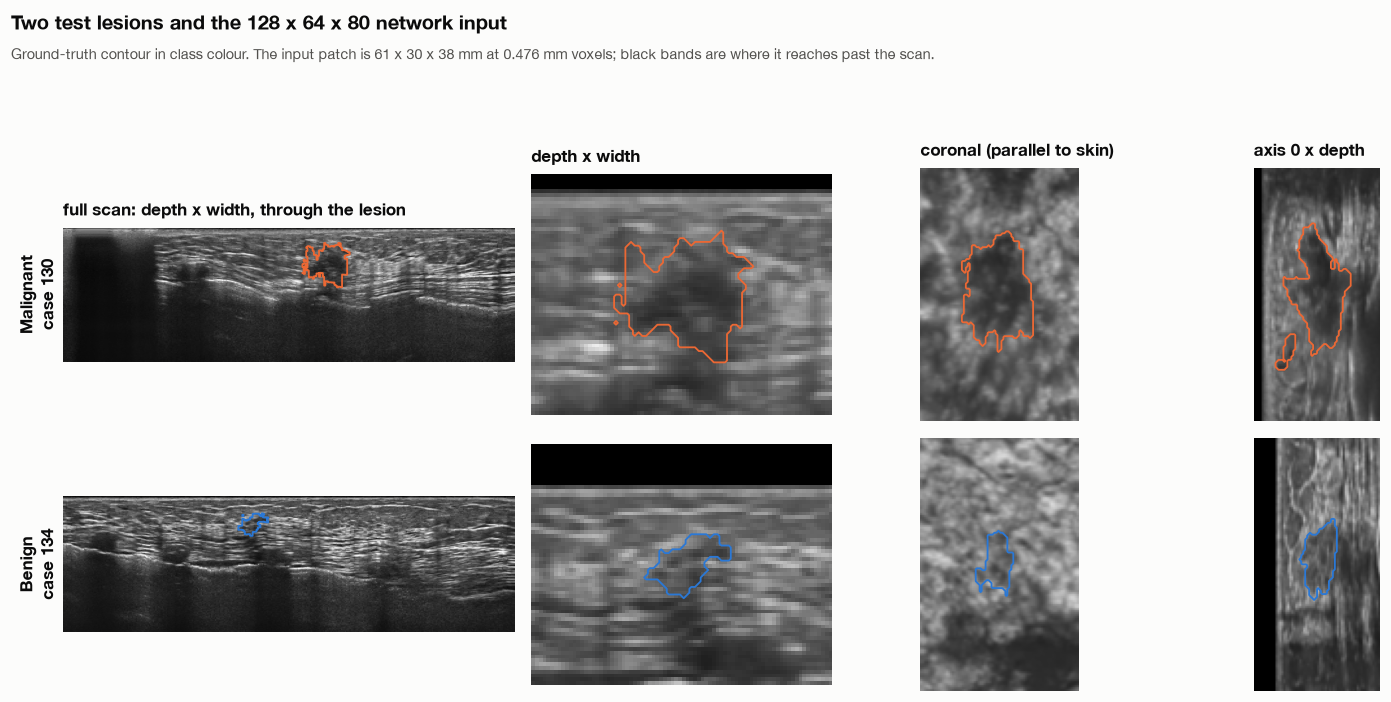

In [9]:
test_ds = TDSC(path=str(DATA_ROOT), split=DataSplits.TEST, download=False)
test_meta = test_ds.metadata
examples = {"M": int(np.flatnonzero(test_meta["label"] == "M")[0]),
            "B": int(np.flatnonzero(test_meta["label"] == "B")[0])}
loaded = {}
for lab, i in examples.items():
    vol, mask, _, _ = test_ds[i]
    loaded[lab] = (vol, mask, *patch(vol, mask))

fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.6), gridspec_kw={"width_ratios": [1.5, 1, 1, 1]})
for row, (lab, (vol, mask, pv, pm)) in enumerate(loaded.items()):
    c = np.round(np.argwhere(mask).mean(0)).astype(int)
    ax = axes[row, 0]                                   # whole scan, plane through the lesion centre
    ax.imshow(vol[c[0]], cmap="gray", aspect=TDSC_SPACING[1] / TDSC_SPACING[2])   # rows 0.073 mm, cols 0.476 mm
    ax.contour(mask[c[0]], [0.5], colors=[MALIGNANT if lab == "M" else BENIGN], linewidths=1.2)
    bare(ax)
    ax.set_ylabel(f"{'Malignant' if lab == 'M' else 'Benign'}\ncase {test_meta.index[examples[lab]]}",
                  fontsize=11, weight="bold", color=INK)
    if row == 0:
        ax.set_title("full scan: depth x width, through the lesion")
    h = np.array(pv.shape) // 2
    planes = [(pv[h[0]], pm[h[0]], "depth x width"), (pv[:, h[1]], pm[:, h[1]], "coronal (parallel to skin)"),
              (pv[:, :, h[2]], pm[:, :, h[2]], "axis 0 x depth")]
    for k, (img, m, title) in enumerate(planes):
        ax = axes[row, k + 1]
        ax.imshow(img.astype(np.float32), cmap="gray", vmin=0, vmax=1)
        ax.contour(m.astype(np.float32), [0.5], colors=[MALIGNANT if lab == "M" else BENIGN], linewidths=1.2)
        bare(ax)
        if row == 0:
            ax.set_title(title)
top = fig_title(fig, "Two test lesions and the 128 x 64 x 80 network input",
                "Ground-truth contour in class colour. The input patch is 61 x 30 x 38 mm at 0.476 mm voxels; black bands are where it reaches past the scan.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

**Augmentation.** During training each pair is flipped at random on every axis and scaled by a factor in
[0.8, 1.2] (`train.augment`), identically for volume and mask. Four draws for the malignant example:

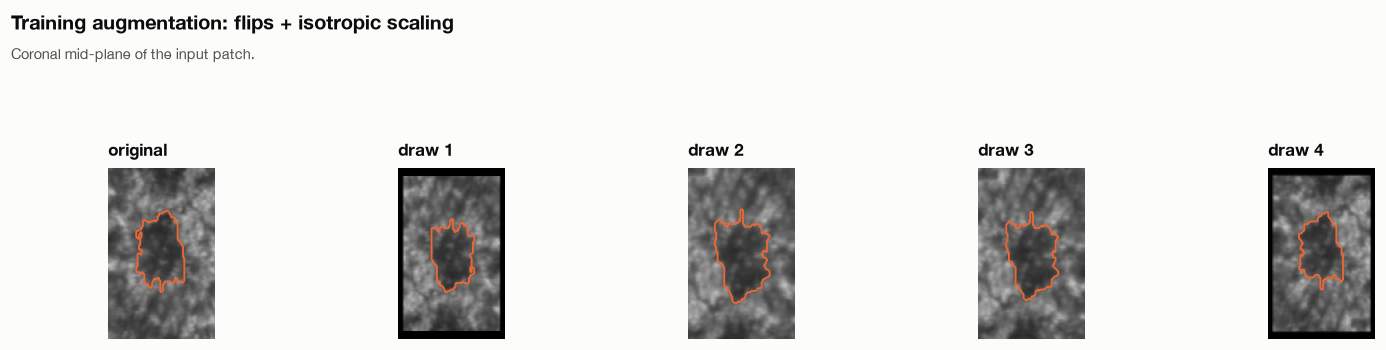

In [10]:
torch.manual_seed(1); np.random.seed(1)
_, _, pv, pm = loaded["M"]
v0, m0 = torch.as_tensor(pv.astype(np.float32))[None], torch.as_tensor(pm.astype(np.float32))[None]
fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.4))
draws = [(v0, m0)] + [augment(v0, m0) for _ in range(4)]
for k, (ax, (v, m)) in enumerate(zip(axes, draws)):
    ax.imshow(v[0, :, 32].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.contour(m[0, :, 32].numpy(), [0.5], colors=[MALIGNANT], linewidths=1.2)
    ax.set_title("original" if k == 0 else f"draw {k}")
    bare(ax)
top = fig_title(fig, "Training augmentation: flips + isotropic scaling", "Coronal mid-plane of the input patch.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

## 6. Results (Kaggle)

Everything in this section is loaded from `../results/zhou2021/`, the output of the Kaggle kernel
`simayousef/zhou2021-multitask` (100 epochs x 3 seeds, about 4 h on the Kaggle GPU):

- `zhou2021_results.csv`: test metrics per seed and for the mean of the three seeds' probabilities
- `zhou2021_probs_seed{0,1,2}.npy`: p(malignant) for the 70 test volumes, in TDSC Test order (cases 130-199)
- `train_loss.csv`: training loss every 10 epochs, parsed from the kernel log

### 6.1 Training curves

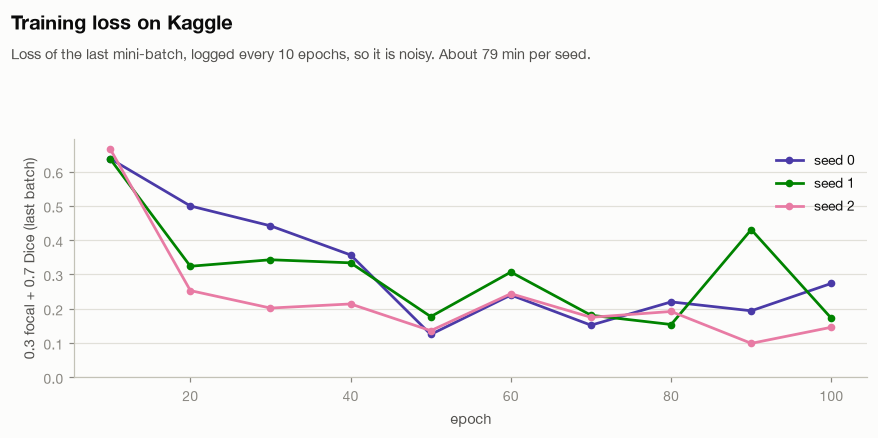

In [11]:
loss = pd.read_csv(RESULTS / "train_loss.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
for s, c in zip(SEEDS, SEED_COLORS):
    d = loss[loss.seed == s]
    ax.plot(d.epoch, d.loss, "o-", color=c, ms=4, lw=1.8, label=f"seed {s}")
ax.set_xlabel("epoch"); ax.set_ylabel("0.3 focal + 0.7 Dice (last batch)")
ax.set_ylim(0, None); value_grid(ax); ax.legend()
minutes = loss.groupby("seed").time_s.max().diff().dropna().mean() / 60
top = fig_title(fig, "Training loss on Kaggle",
                f"Loss of the last mini-batch, logged every 10 epochs, so it is noisy. About {minutes:.0f} min per seed.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

### 6.2 Test metrics per seed

In [12]:
y = (test_meta["label"] == "M").to_numpy().astype(int)          # 1 = malignant
probs = {s: np.load(RESULTS / f"zhou2021_probs_seed{s}.npy") for s in SEEDS}
ensemble = np.mean(list(probs.values()), 0)

stored = pd.read_csv(RESULTS / "zhou2021_results.csv", index_col=0)
recomputed = pd.DataFrame({**{f"seed {s}": metrics(y, p) for s, p in probs.items()},
                           "mean of seeds": metrics(y, ensemble)}).T
assert np.allclose(recomputed.values, stored[recomputed.columns].values, atol=1e-4)   # labels line up with Kaggle

summary = stored.copy()
seed_rows = stored.loc[[f"seed {s}" for s in SEEDS]]
summary.loc["seed mean ± sd"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(seed_rows.mean(), seed_rows.std())]
lo, hi = auc_ci(y, ensemble)
print(f"{y.sum()} malignant / {len(y) - y.sum()} benign test volumes;  ensemble AUC 95% bootstrap CI {lo:.3f}-{hi:.3f}")
summary

40 malignant / 30 benign test volumes;  ensemble AUC 95% bootstrap CI 0.531-0.790


,AUC,Acc,Prec,Sens,Spec,F1,Dice
seed 0,0.6458,0.6571,0.8077,0.525,0.8333,0.6364,0.7237
seed 1,0.6625,0.6429,0.6667,0.75,0.5,0.7059,0.7403
seed 2,0.685,0.5857,0.7391,0.425,0.8,0.5397,0.7337
mean of seeds,0.6658,0.6286,0.7188,0.575,0.7,0.6389,0.7326
seed mean ± sd,0.664 ± 0.020,0.629 ± 0.038,0.738 ± 0.071,0.567 ± 0.166,0.711 ± 0.184,0.627 ± 0.083,0.733 ± 0.008


### 6.3 Paper vs ours

Paper numbers are CMSVNetIter from Table 3 and Fig. 8 (AUC). They come from four-fold cross-validation on the paper's
private data, so the comparison is context, not a like-for-like target. REC is our Sens, PRE our Prec, and our Spec is
1 - FPR.

In [13]:
paper = pd.Series({"AUC": 0.787, "Acc": 0.741, "Prec": 0.826, "Sens": 0.798, "Spec": 1 - 0.392, "F1": 0.811,
                   "Dice": 0.778}, name="Zhou et al. 2021, Table 3 + Fig. 8")
seeds = stored.loc[[f"seed {s}" for s in SEEDS], paper.index]
cmp = pd.DataFrame({"paper": paper, "ours (mean of seeds)": stored.loc["mean of seeds", paper.index],
                    "ours (seed sd)": seeds.std()})
cmp["ours - paper"] = cmp["ours (mean of seeds)"] - cmp["paper"]
print(f"paper AUC {paper.AUC} is {'inside' if lo <= paper.AUC <= hi else 'outside'} our 95% CI {lo:.3f}-{hi:.3f}")
cmp.round(3)

paper AUC 0.787 is inside our 95% CI 0.531-0.790


,paper,ours (mean of seeds),ours (seed sd),ours - paper
AUC,0.787,0.666,0.020,-0.121
Acc,0.741,0.629,0.038,-0.112
Prec,0.826,0.719,0.071,-0.107
Sens,0.798,0.575,0.166,-0.223
Spec,0.608,0.700,0.184,0.092
F1,0.811,0.639,0.083,-0.172
Dice,0.778,0.733,0.008,-0.045


### 6.4 ROC curves and predicted probabilities

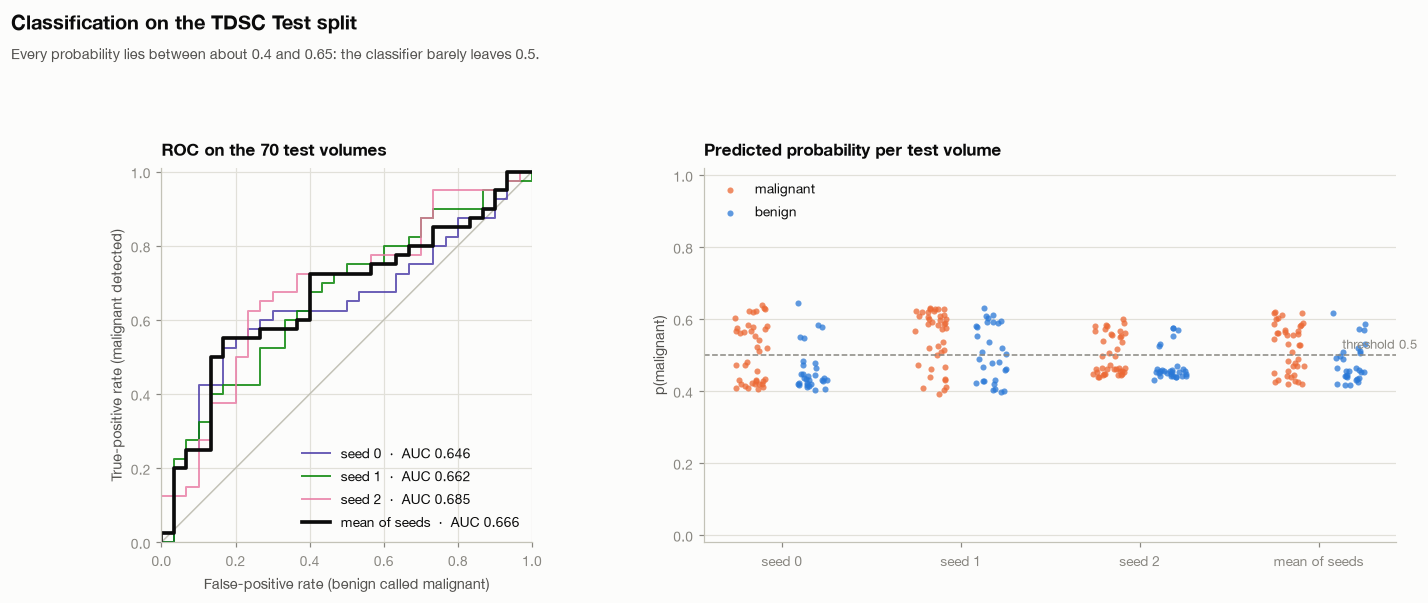

range of p(malignant): 0.39-0.65
share called malignant at 0.5: {0: 0.37, 1: 0.64, 2: 0.33}   true share: 0.57
correlation of seed probabilities:
 [[1.   0.79 0.82]
 [0.79 1.   0.75]
 [0.82 0.75 1.  ]]


In [14]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
for s, c in zip(SEEDS, SEED_COLORS):
    fpr, tpr, _ = roc_curve(y, probs[s])
    ax.plot(fpr, tpr, color=c, lw=1.3, alpha=0.8, label=f"seed {s}  ·  AUC {roc_auc_score(y, probs[s]):.3f}")
fpr, tpr, _ = roc_curve(y, ensemble)
ax.plot(fpr, tpr, color=INK, lw=2.4, label=f"mean of seeds  ·  AUC {roc_auc_score(y, ensemble):.3f}")
ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.set_xlabel("False-positive rate (benign called malignant)")
ax.set_ylabel("True-positive rate (malignant detected)")
value_grid(ax, "both"); ax.legend(loc="lower right")
ax.set_title("ROC on the 70 test volumes")

rng = np.random.default_rng(0)
for k, s in enumerate((*SEEDS, "mean")):
    p = ensemble if s == "mean" else probs[s]
    for lab, col, off in ((1, MALIGNANT, -0.17), (0, BENIGN, 0.17)):
        pts = p[y == lab]
        ax2.scatter(k + off + rng.uniform(-0.09, 0.09, len(pts)), pts, s=16, color=col, alpha=0.75, lw=0,
                    label=("malignant" if lab else "benign") if k == 0 else None)
ax2.axhline(0.5, color=MUTED, lw=1, ls="--")
ax2.text(3.55, 0.51, "threshold 0.5", color=MUTED, fontsize=8.5, ha="right", va="bottom")
ax2.set_xticks(range(4), [f"seed {s}" for s in SEEDS] + ["mean of seeds"])
ax2.set_ylim(-0.02, 1.02); ax2.set_ylabel("p(malignant)")
value_grid(ax2); ax2.legend(loc="upper left")
ax2.set_title("Predicted probability per test volume")
top = fig_title(fig, "Classification on the TDSC Test split",
                "Every probability lies between about 0.4 and 0.65: the classifier barely leaves 0.5.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

print(f"range of p(malignant): {min(p.min() for p in probs.values()):.2f}-{max(p.max() for p in probs.values()):.2f}")
print("share called malignant at 0.5:", {s: round(float((probs[s] >= 0.5).mean()), 2) for s in SEEDS},
      "  true share:", round(float(y.mean()), 2))
print("correlation of seed probabilities:\n", np.corrcoef([probs[s] for s in SEEDS]).round(2))

### 6.5 Segmentation on the test split

From `zhou2021_seed{0,1,2}_test.npz`, written by the Kaggle kernel `simayousef/zhou2021-eval`. It re-evaluated the
finished checkpoints without training, and the test below confirms it gives the same probabilities as the training
run. Each row is the coronal mid-plane of one test volume (seed 0): ground truth in red, predicted tumor probability
in yellow contours at 0.5. Dice is for the whole volume, so a slice can look better or worse than its score.

per seed mean Dice [0.724 0.74  0.734]   volumes with Dice < 0.1 per seed: [2 2 3]


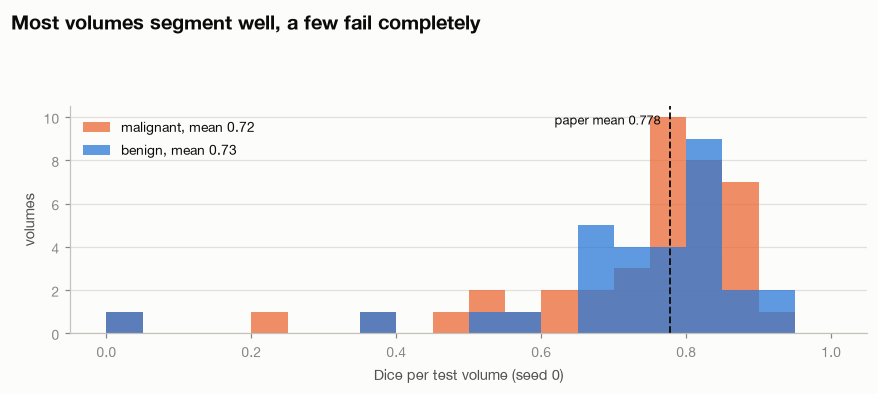

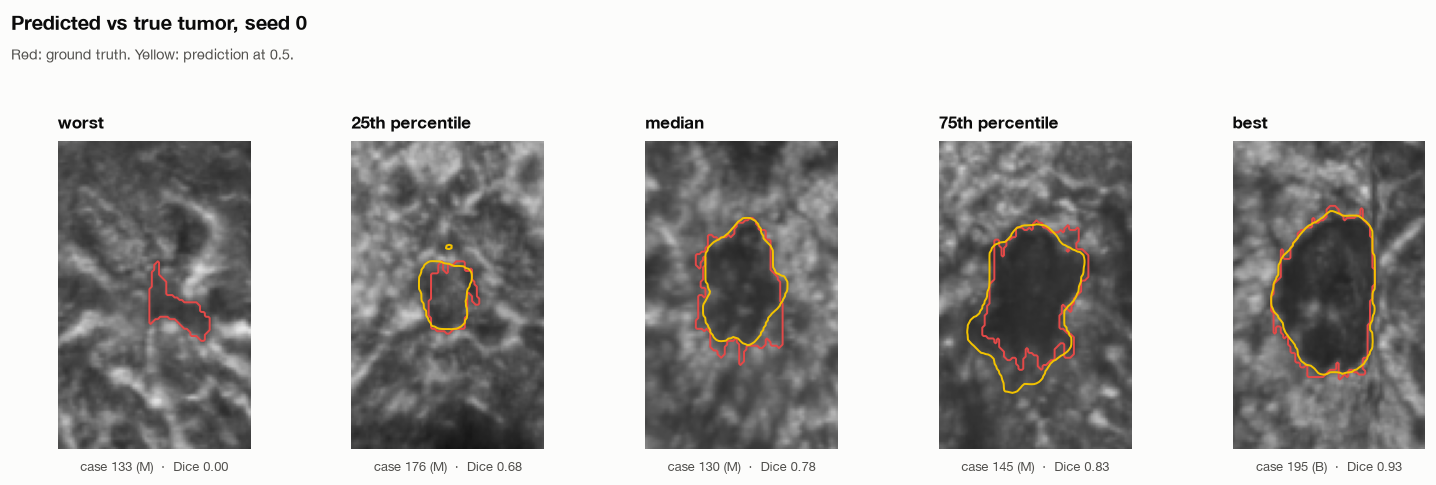

In [15]:
test_out = {s: np.load(RESULTS / f"zhou2021_seed{s}_test.npz") for s in SEEDS}
for s in SEEDS:
    assert np.allclose(test_out[s]["prob"], probs[s], atol=1e-5)
dice = np.stack([test_out[s]["dice"] for s in SEEDS])
print("per seed mean Dice", dice.mean(1).round(3), "  volumes with Dice < 0.1 per seed:", (dice < 0.1).sum(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(0, 1, 21)
ax.hist(dice[0][y == 1], bins, color=MALIGNANT, alpha=0.75, label=f"malignant, mean {dice[0][y == 1].mean():.2f}")
ax.hist(dice[0][y == 0], bins, color=BENIGN, alpha=0.75, label=f"benign, mean {dice[0][y == 0].mean():.2f}")
ax.axvline(0.778, color=INK, lw=1.2, ls="--"); ax.text(0.77, ax.get_ylim()[1] * 0.92, "paper mean 0.778 ", ha="right", fontsize=8.5)
ax.set_xlabel("Dice per test volume (seed 0)"); ax.set_ylabel("volumes"); value_grid(ax); ax.legend(loc="upper left")
top = fig_title(fig, "Most volumes segment well, a few fail completely")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

d = test_out[0]
order = np.argsort(d["dice"])
picks = [order[0], order[len(order) // 4], order[len(order) // 2], order[3 * len(order) // 4], order[-1]]
names = ["worst", "25th percentile", "median", "75th percentile", "best"]
fig, axes = plt.subplots(1, 5, figsize=(13.5, 4.4))
for ax, i, name in zip(axes, picks, names):
    ax.imshow(d["vol_mid"][i].astype(np.float32), cmap="gray", vmin=0, vmax=1)
    if d["mask_mid"][i].max() > 0.5:
        ax.contour(d["mask_mid"][i].astype(np.float32), [0.5], colors=["#e34948"], linewidths=1.3)
    if d["seg_mid"][i].max() > 0.5:
        ax.contour(d["seg_mid"][i].astype(np.float32), [0.5], colors=["#f2c200"], linewidths=1.3)
    ax.set_title(name); bare(ax)
    ax.text(0.5, -0.03, f"case {test_meta.index[i]} ({'M' if y[i] else 'B'})  ·  Dice {d['dice'][i]:.2f}",
            transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color=INK_2)
top = fig_title(fig, "Predicted vs true tumor, seed 0", "Red: ground truth. Yellow: prediction at 0.5.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

### 6.6 Ablations (paper Table 1, Table 3, Fig. 8)

Ours is one seed (0) on the TDSC Test split, from the Kaggle kernels `simayousef/zhou2021-ablations` and
`zhou2021-ablations2`; the CMSVNetIter row is seed 0 of the main run. Seed-to-seed sd of the full method is 0.02 in
AUC, and the bootstrap CI below is much wider, so **single-seed differences between these models are mostly noise**.
The lambda = 0.7 row is from the paper's Table 5, which reports no AUC.

In [16]:
NAMES = {"vnet": "VNet", "clsnet": "ClsNet", "cvnet": "CVNet", "cvnetiter": "CVNetIter", "cmsvnet": "CMSVNet",
         "lam07": "CMSVNetIter, lambda 0.7"}
paper_abl = pd.DataFrame({
    "Dice": [0.645, np.nan, 0.668, 0.761, 0.690, 0.778, 0.762], "AUC": [np.nan, 0.525, 0.676, 0.664, 0.683, 0.787, np.nan],
    "Acc": [np.nan, 0.594, 0.700, 0.700, 0.718, 0.741, 0.694], "F1": [np.nan, 0.711, 0.797, 0.797, 0.808, 0.811, 0.782],
}, index=["VNet", "ClsNet", "CVNet", "CVNetIter", "CMSVNet", "CMSVNetIter", "CMSVNetIter, lambda 0.7"])

ours_abl = pd.read_csv(RESULTS / "zhou2021_ablations.csv", index_col=0).rename(index=NAMES)
ours_abl.loc["CMSVNetIter"] = stored.loc["seed 0", ours_abl.columns]
abl_out = np.load(RESULTS / "zhou2021_ablation_outputs.npz")
abl_probs = {NAMES[n]: abl_out[f"prob_{n}"] for n in NAMES if n != "vnet"} | {"CMSVNetIter": probs[0]}
table = paper_abl.add_prefix("paper ").join(ours_abl[["Dice", "AUC", "Acc", "F1"]].add_prefix("ours "))
table["ours AUC 95% CI"] = [("%.2f-%.2f" % tuple(auc_ci(y, abl_probs[m]))) if m in abl_probs else "" for m in table.index]
table[["paper Dice", "ours Dice", "paper AUC", "ours AUC", "ours AUC 95% CI", "paper Acc", "ours Acc", "paper F1", "ours F1"]].round(3)

,paper Dice,ours Dice,paper AUC,ours AUC,ours AUC 95% CI,paper Acc,ours Acc,paper F1,ours F1
VNet,0.645,0.698,NaN,NaN,,NaN,NaN,NaN,NaN
ClsNet,NaN,NaN,0.525,0.718,0.59-0.84,0.594,0.586,0.711,0.473
CVNet,0.668,0.714,0.676,0.712,0.58-0.83,0.700,0.614,0.797,0.526
CVNetIter,0.761,0.732,0.664,0.667,0.52-0.79,0.700,0.586,0.797,0.554
CMSVNet,0.690,0.660,0.683,0.740,0.61-0.85,0.718,0.629,0.808,0.594
CMSVNetIter,0.778,0.724,0.787,0.646,0.52-0.78,0.741,0.657,0.811,0.636
"CMSVNetIter, lambda 0.7",0.762,0.725,NaN,0.703,0.57-0.81,0.694,0.600,0.782,0.576


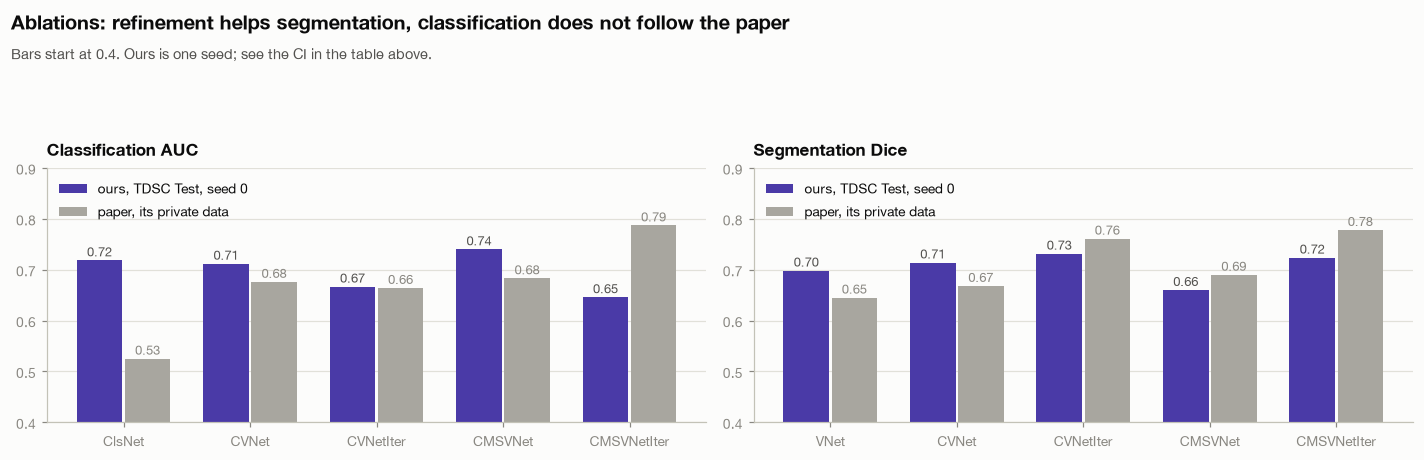

In [17]:
order = ["VNet", "ClsNet", "CVNet", "CVNetIter", "CMSVNet", "CMSVNetIter"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, col, title in ((axes[0], "AUC", "Classification AUC"), (axes[1], "Dice", "Segmentation Dice")):
    names = [m for m in order if not np.isnan(paper_abl.loc[m, col])]
    xx = np.arange(len(names))
    ax.bar(xx - 0.19, ours_abl.loc[names, col], 0.36, color=ACCENT, label="ours, TDSC Test, seed 0")
    ax.bar(xx + 0.19, paper_abl.loc[names, col], 0.36, color=REFERENCE, label="paper, its private data")
    for x_, a_, b_ in zip(xx, ours_abl.loc[names, col], paper_abl.loc[names, col]):
        ax.text(x_ - 0.19, a_ + 0.008, f"{a_:.2f}", ha="center", fontsize=8.5, color=INK_2)
        ax.text(x_ + 0.19, b_ + 0.008, f"{b_:.2f}", ha="center", fontsize=8.5, color=MUTED)
    ax.set_xticks(xx, names); ax.set_ylim(0.4, 0.9); ax.set_title(title); value_grid(ax); ax.legend(loc="upper left")
top = fig_title(fig, "Ablations: refinement helps segmentation, classification does not follow the paper",
                "Bars start at 0.4. Ours is one seed; see the CI in the table above.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

### 6.7 Why the classifier is weak: training diagnostics

The kernel `zhou2021-ablations` re-trained CMSVNetIter (seed 0) on 104 volumes, with 26 of Train+Validation held out
and Test untouched. These curves answer the question from the earlier run: does the classification head overfit, or
does it barely train? Train AUC comes from the training passes, so it includes dropout and augmentation. The held-out
AUC rests on 26 volumes, so it is noisy, and its single best epoch means little.

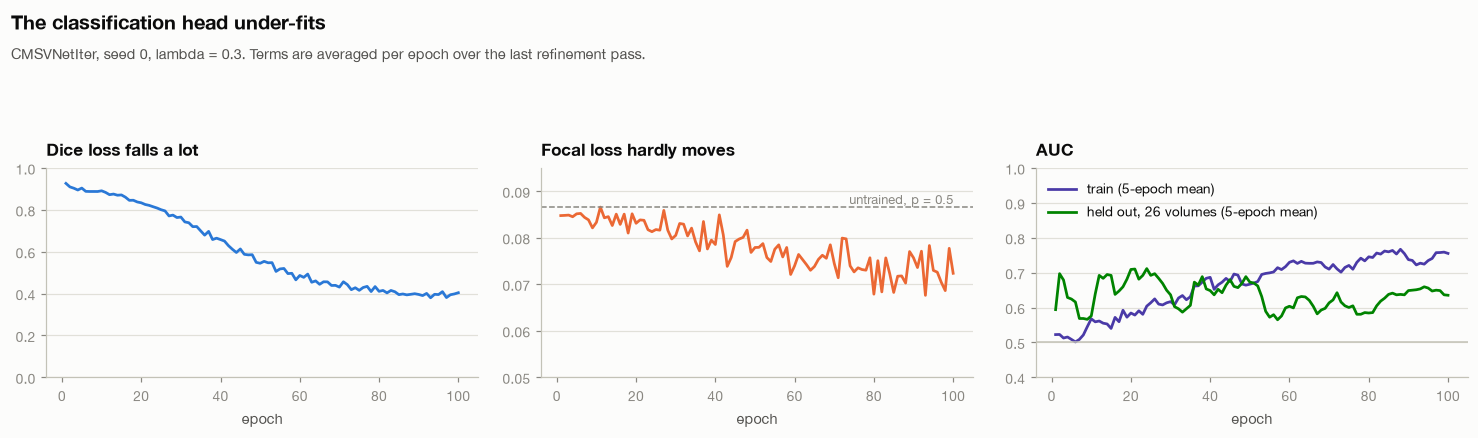

last 10 epochs: focal 0.073, Dice loss 0.395, train AUC 0.74, held-out AUC 0.65, held-out Dice 0.70, p range 0.37-0.69
first epoch focal 0.085
this run on Test: {'AUC': 0.688, 'Acc': 0.571, 'Prec': 0.75, 'Sens': 0.375, 'Spec': 0.833, 'F1': 0.5, 'Dice': 0.699}


In [18]:
hist = pd.read_csv(RESULTS / "zhou2021_seed0_val_history.csv")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
ax = axes[0]
ax.plot(hist.epoch, hist.dice_loss, color=BENIGN, lw=1.8)
ax.set_title("Dice loss falls a lot"); ax.set_ylim(0, 1); ax.set_xlabel("epoch"); value_grid(ax)
ax = axes[1]
ax.plot(hist.epoch, hist.focal, color=MALIGNANT, lw=1.8)
ax.axhline(0.25 * np.log(2) * 0.5, color=MUTED, ls="--", lw=1)
ax.text(100, 0.25 * np.log(2) * 0.5 + 0.0006, "untrained, p = 0.5", ha="right", fontsize=8.5, color=MUTED)
ax.set_title("Focal loss hardly moves"); ax.set_ylim(0.05, 0.095); ax.set_xlabel("epoch"); value_grid(ax)
ax = axes[2]
ax.plot(hist.epoch, hist.train_auc.rolling(5, min_periods=1).mean(), color=ACCENT, lw=1.8, label="train (5-epoch mean)")
ax.plot(hist.epoch, hist.val_auc.rolling(5, min_periods=1).mean(), color=SEED_COLORS[1], lw=1.8, label="held out, 26 volumes (5-epoch mean)")
ax.axhline(0.5, color=AXIS, lw=1); ax.set_ylim(0.4, 1); ax.set_title("AUC"); ax.set_xlabel("epoch"); value_grid(ax); ax.legend(loc="upper left")
top = fig_title(fig, "The classification head under-fits", "CMSVNetIter, seed 0, lambda = 0.3. Terms are averaged per epoch over the last refinement pass.")
fig.tight_layout(rect=[0, 0, 1, top])
plt.show()

last = hist.tail(10).mean()
print(f"last 10 epochs: focal {last.focal:.3f}, Dice loss {last.dice_loss:.3f}, train AUC {last.train_auc:.2f}, "
      f"held-out AUC {last.val_auc:.2f}, held-out Dice {last.val_dice:.2f}, p range {hist.p_min.tail(10).min():.2f}-{hist.p_max.tail(10).max():.2f}")
print("first epoch focal", round(hist.focal.iloc[0], 3))
print("this run on Test:", pd.read_csv(RESULTS / "zhou2021_val_results.csv", index_col=0).loc["seed 0"].round(3).to_dict())

## 7. Protocol and how to re-run

- **Data:** TDSC-ABUS 2023 (`tdsc_abus2023_pytorch`). Train on Train + Validation (130 volumes), report once on the
  official Test split (70: 40 malignant, 30 benign). Malignant is the positive class.
- **Seeds:** 3 (0, 1, 2). Reported per seed and for the mean of the three probability vectors. AUC 95% CI by
  bootstrap over test volumes (`abus_classification.protocol.auc_ci`, 1000 resamples).
- **Input:** the lesion cache `data/eswa2025.npz` (`abus_classification.data.lesion_cache`), built by the Kaggle
  kernel `simayousef/eswa2025-reproduction` and reused by the Zhou kernel through `kernel_sources`.
- **Re-run on Kaggle** (GPU, about 80 min per seed): `kaggle/zhou2021/run.py` clones branch `feat/zhou2021`, links
  the cache and calls `main(100, ckpt_dir="/kaggle/working")`. It saves a checkpoint every 10 epochs and resumes
  from any `zhou2021_seed*.pt` attached as kernel input.

```bash
kaggle kernels push -p kaggle/zhou2021
```

```bash
kaggle kernels output simayousef/zhou2021-multitask -p results/zhou2021
```

- **Run locally** (not recommended, hours on a laptop): `python -m abus_classification.papers.zhou2021 --epochs 100`.
- **Stored results:** `results/zhou2021/`: metrics, per-seed test outputs, ablation results and per-epoch histories.
  The checkpoints stay in the Kaggle kernel output and are not committed.
- **Other kernels:** `kaggle/zhou2021-eval` (re-evaluates the trained checkpoints, no training),
  `kaggle/zhou2021-ablations` (held-out diagnostics, ablations) and `kaggle/zhou2021-ablations2` (ClsNet, CVNetIter).
  `zhou2021-ablations` also contains an older ClsNet variant with the wrong features, which is left out of the results.

## 8. Open issues

1. **Classification is below the paper, but not clearly so.** Test AUC is 0.666 for the mean of seeds against the
   paper's 0.787, and 0.787 is inside our 95% CI (0.53-0.79). Accuracy is 0.63 against 0.741, Dice 0.73 against 0.778.
   The data, split and evaluation all differ. Other methods reach 0.86 on our same split (Tan 2012 SVM, the ESWA 2025
   CNN), so this method is weak here, as it is in the paper.
2. **The paper's ablation story reproduces for segmentation, not for classification** (Section 6.6, one seed).
   Refinement raises Dice (CVNet to CVNetIter, CMSVNet to CMSVNetIter) as in the paper. For classification, our full
   method is not the best: encoder-only ClsNet (0.72) and CMSVNet without refinement (0.74) score above CMSVNetIter
   (0.65 on seed 0), where the paper has ClsNet lowest and CMSVNetIter highest. All these CIs overlap, so we cannot
   claim the order is reversed, only that the paper's gain is not visible here. Repeating them on 3 seeds would settle more.
3. **The classification head under-fits (Section 6.7).** The focal loss only falls from 0.085 to about 0.07, train AUC
   is about 0.75 after 100 epochs, and probabilities stay within about 0.37-0.69. Held-out AUC is about 0.65, so
   overfitting is not the main problem. Untested explanations:
   - *Small inputs and a small loss.* L2-normalised features (Eq. 1) have small values and the focal loss at p = 0.5 is
     only about 0.085, so gradients to the head are small at lr 1e-4. A higher head learning rate is the cheapest test.
   - *More weight does not obviously help.* lambda = 0.7 gave AUC 0.70 on one seed, inside the noise.
   - *Smaller field of view:* 38 mm on the axis where the paper has 64 mm.
   - *Weaker augmentation:* no rotation or elastic deformation.
4. **Unexplained:** without refinement, the training Dice loss stays high (about 0.67-0.69) although test Dice is
   0.66-0.71. Train-mode batch norm with batch size 2 is a possible cause; this was not checked.
5. **Unstable threshold.** The seeds call 37%, 64% and 33% of the test set malignant (true share 57%). This affects
   accuracy-type metrics, not AUC.
6. **Not run:** the paper's Table 2 (N = 0-4), Table 4 (other stage combinations), Table 5 beyond lambda = 0.3 and 0.7,
   Table 6 (other multi-task methods), and 3 seeds for the ablations.


## 9. Challenge benchmark

The TDSC-ABUS 2023 evaluation (`abus_classification/challenge.py`, explained in `challenge-benchmark.ipynb`), placed on
the published leaderboard. **Classification only:** the Kaggle runs saved only patches, so full-volume segmentation and
detection are not scored, and the Dice in Section 6 is on patches, not comparable with the challenge's. The patches are
also centred on the ground truth, which challenge teams did not have.

In [19]:
from abus_classification import challenge
challenge.benchmark({"Zhou 2021, CMSVNetIter": challenge.classification(y, ensemble)})[["ACC", "AUC", "Cls_Score", "Cls_Rank"]].round(3)

,ACC,AUC,Cls_Score,Cls_Rank
"Zhou 2021, CMSVNetIter",0.629,0.666,0.353,6/9
